# 03 · The deep model, ablations and calibration

**Hypothesis.** A neural network with *learned team embeddings* can capture club-specific effects that a hand-built Elo rating and form features miss, and so should beat the baselines of notebook 02.

**How we keep the comparison fair.** Same features, same chronological split, same validation-only model selection and early stopping, and a random-search budget comparable to the grids used for the baselines. Neural nets are seed-sensitive, so every network number is reported over **5 seeds** (mean ± std) and as a **5-seed ensemble**. Whatever the outcome, it is reported as measured.

## Architecture

```
numeric features (17, standardised) ──────────────┐
home-team id ─► Embedding (shared table) ─────────┼─► Dense ─ Dropout ─ Dense ─ Dropout ─► softmax(3)
away-team id ─► Embedding (same table)  ──────────┘
```

* Clubs seen fewer than 5 times in the training data share an `<UNK>` embedding, which is also what any club first seen after the training period receives.
* L2 on weights and embeddings, dropout, **early stopping on validation loss** with best-weights restore, Adam.
* CPU only, TensorFlow/Keras 3, deterministic ops, seeds fixed.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ucl import experiments as X
from ucl import plotting as P
from ucl.config import MODELS_DIR, SEED
from ucl.evaluation import (
    bootstrap_ci,
    log_loss,
    paired_bootstrap,
    per_match_log_loss,
    score_all,
)
from ucl.models import Ensemble, MLPModel
from ucl.predict import save_artifact

P.apply_style()
pd.set_option("display.width", 140)
T0 = time.perf_counter()
ds = X.load_dataset()
tr, va, te = ds.train, ds.val, ds.test
hp = X.load_json("baseline_hparams.json")
baselines = X.fit_baselines(tr, va, hp)
display(
    Markdown(
        f"Train {len(tr)} · validation {len(va)} · test {len(te)} matches. Elo parameters from notebook 02: `{ds.elo_params}`."
    )
)

Train 2880 · validation 494 · test 753 matches. Elo parameters from notebook 02: `EloParams(k=15.0, home_advantage=60.0, season_regression=0.0, country_prior_weight=0.5)`.

## Hyper-parameter search (validation only)

Random search over embedding size, depth/width, dropout, L2, learning rate and batch size. Each configuration is trained with 2 seeds; its score is the validation log-loss of the 2-seed average.

In [2]:
t = time.perf_counter()
best_cfg, trials = X.tune_mlp(tr, va, n_trials=12, n_seeds=2)
X.save_json(best_cfg.to_json(), "mlp_config.json")
display(Markdown(f"12 trials in {time.perf_counter() - t:.0f}s."))
trials.drop(columns="trial").round(4).head(6)

12 trials in 40s.

,embedding_dim,hidden,dropout,l2,lr,batch_size,mean_best_epoch,val_log_loss,seconds
0,16,"(16,)",0.5,0.010,0.003,128,25.5,0.9462,3.0624
1,4,"(32,)",0.1,0.001,0.003,32,3.0,0.9463,2.8111
2,8,"(32, 16)",0.1,0.001,0.003,32,4.5,0.9466,3.1415
3,4,"(32,)",0.1,0.010,0.003,128,32.0,0.9484,3.5000
4,4,"(32,)",0.3,0.001,0.003,128,8.0,0.9505,2.3332
5,4,"(32, 16)",0.3,0.010,0.001,64,56.5,0.9526,5.4490


In [3]:
display(
    Markdown(
        f"Validation log-loss over the 12 configurations ranges from **{trials.val_log_loss.min():.4f}** to **{trials.val_log_loss.max():.4f}**; "
        f"the best network has {best_cfg.hidden} hidden units, {best_cfg.embedding_dim}-d embeddings, dropout {best_cfg.dropout}, L2 {best_cfg.l2}, lr {best_cfg.lr}. "
        f"Reference on the same split: Elo logistic regression {log_loss(va.y, baselines['Elo + logistic regression'].predict_proba(va)):.4f}, "
        f"gradient boosting {log_loss(va.y, baselines['Gradient boosting'].predict_proba(va)):.4f}."
    )
)

Validation log-loss over the 12 configurations ranges from **0.9462** to **0.9628**; the best network has (16,) hidden units, 16-d embeddings, dropout 0.5, L2 0.01, lr 0.003. Reference on the same split: Elo logistic regression 0.9448, gradient boosting 0.9500.

## Final training: 5 seeds, early stopping, training curves

Thin lines are individual seeds. Training loss includes the L2 penalty (Keras convention), validation loss does not, so the two are not directly comparable in level; what matters is *where validation loss turns around*. Early stopping restores the best epoch.

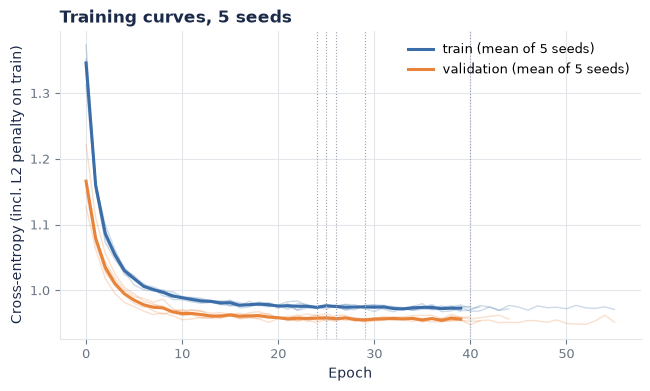

Five networks trained in 8s (1.7s each, CPU). Dotted lines mark each seed's early-stopping epoch.

,best_epoch,epochs_run,val_log_loss,test_log_loss
seed,,,,
2026,26,41,0.9471,0.9326
2027,25,40,0.9460,0.9294
2028,30,45,0.9502,0.9355
2029,27,42,0.9474,0.9346
2030,41,56,0.9428,0.9300


In [4]:
t = time.perf_counter()
SEEDS = [SEED + s for s in range(5)]
members = [MLPModel(best_cfg, seed=s).fit(tr, va) for s in SEEDS]
train_s = time.perf_counter() - t
fig, ax = plt.subplots(figsize=(7.5, 4))
P.training_curves([m.history for m in members], ax=ax)
ax.set_title("Training curves, 5 seeds")
for m in members:
    ax.axvline(m.best_epoch_ - 1, color=P.COLORS["grey"], lw=0.8, ls=":")
P.save(fig, "training_curves")
plt.show()
rows = [
    {
        "seed": m.seed,
        "best_epoch": m.best_epoch_,
        "epochs_run": len(m.history["loss"]),
        "val_log_loss": log_loss(va.y, m.predict_proba(va)),
        "test_log_loss": log_loss(te.y, m.predict_proba(te)),
    }
    for m in members
]
seed_tab = pd.DataFrame(rows).set_index("seed")
display(
    Markdown(
        f"Five networks trained in {train_s:.0f}s ({train_s / 5:.1f}s each, CPU). Dotted lines mark each seed's early-stopping epoch."
    )
)
seed_tab.round(4)

In [5]:
ens = Ensemble(members, name="MLP + team embeddings (x5 ensemble)")
p_va, p_te = ens.predict_proba(va), ens.predict_proba(te)
display(
    Markdown(
        f"Single networks: validation **{seed_tab.val_log_loss.mean():.4f} ± {seed_tab.val_log_loss.std():.4f}**, test **{seed_tab.test_log_loss.mean():.4f} ± {seed_tab.test_log_loss.std():.4f}** (mean ± std over seeds). "
        f"5-seed ensemble: validation **{log_loss(va.y, p_va):.4f}**, test **{log_loss(te.y, p_te):.4f}**. "
        f"The seed-to-seed spread is the noise floor: gaps between models smaller than this are not evidence of anything."
    )
)

Single networks: validation **0.9467 ± 0.0026**, test **0.9324 ± 0.0027** (mean ± std over seeds). 5-seed ensemble: validation **0.9460**, test **0.9316**. The seed-to-seed spread is the noise floor: gaps between models smaller than this are not evidence of anything.

## Ablation: what is the network actually using?

Starting from the tuned network, remove one ingredient at a time (same hyper-parameters, 5 seeds each). Note the hyper-parameters were tuned for the *full* model, which if anything favours it.

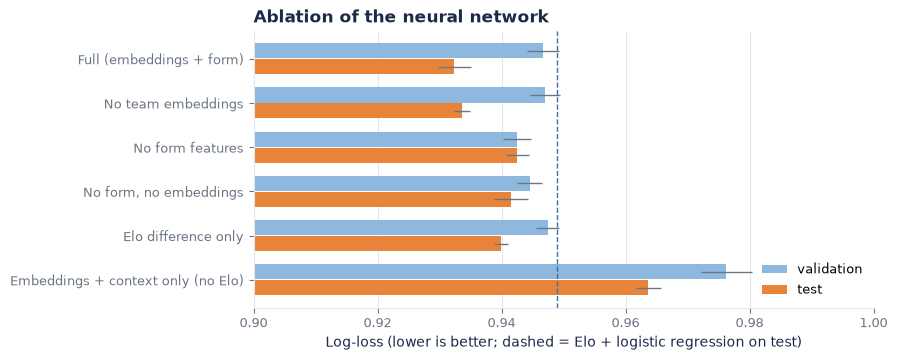

Ablation: 6 variants x 5 seeds in 56s.

,val_mean,val_std,test_mean,test_std,ensemble_test
variant,,,,,
Full (embeddings + form),0.9467,0.0026,0.9324,0.0027,0.9316
No team embeddings,0.9470,0.0024,0.9336,0.0014,0.9329
No form features,0.9425,0.0023,0.9426,0.0019,0.9421
"No form, no embeddings",0.9445,0.0021,0.9416,0.0028,0.9411
Elo difference only,0.9475,0.0019,0.9399,0.0012,0.9396
Embeddings + context only (no Elo),0.9763,0.0041,0.9637,0.0020,0.9628


In [6]:
t = time.perf_counter()
abl_rows = []
for name, cfg in X.ablation_configs(best_cfg).items():
    ms = [MLPModel(cfg, seed=s).fit(tr, va) for s in SEEDS]
    v = [log_loss(va.y, m.predict_proba(va)) for m in ms]
    te_ = [log_loss(te.y, m.predict_proba(te)) for m in ms]
    abl_rows.append(
        {
            "variant": name,
            "val_mean": np.mean(v),
            "val_std": np.std(v, ddof=1),
            "test_mean": np.mean(te_),
            "test_std": np.std(te_, ddof=1),
            "ensemble_test": log_loss(te.y, np.mean([m.predict_proba(te) for m in ms], axis=0)),
        }
    )
abl = pd.DataFrame(abl_rows).set_index("variant")
abl_s = time.perf_counter() - t

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(abl))[::-1]
ax.barh(
    y + 0.18,
    abl.val_mean,
    0.34,
    xerr=abl.val_std,
    color=P.COLORS["sky"],
    label="validation",
    error_kw=dict(lw=1, ecolor=P.MUTED),
)
ax.barh(
    y - 0.18,
    abl.test_mean,
    0.34,
    xerr=abl.test_std,
    color=P.COLORS["orange"],
    label="test",
    error_kw=dict(lw=1, ecolor=P.MUTED),
)
ax.set_yticks(y, abl.index)
ax.set_xlim(0.90, 1.0)
ax.grid(axis="y", visible=False)
ax.axvline(
    log_loss(te.y, baselines["Elo + logistic regression"].predict_proba(te)),
    color=P.COLORS["blue"],
    ls="--",
    lw=1,
)
ax.set_xlabel("Log-loss (lower is better; dashed = Elo + logistic regression on test)")
ax.set_title("Ablation of the neural network")
ax.legend(loc="lower right")
P.save(fig, "ablation")
plt.show()
display(Markdown(f"Ablation: {len(abl)} variants x 5 seeds in {abl_s:.0f}s."))
abl.round(4)

In [7]:
full, no_emb = abl.loc["Full (embeddings + form)"], abl.loc["No team embeddings"]
no_form = abl.loc["No form features"]
no_elo = abl.loc["Embeddings + context only (no Elo)"]
noise = max(full.test_std, no_emb.test_std)
display(
    Markdown(
        f"* **Team embeddings:** removing them changes test log-loss from {full.test_mean:.4f} to {no_emb.test_mean:.4f} "
        f"(seed std ≈ {noise:.4f}). {'The effect is within seed noise: the embeddings do not add reliable information beyond Elo.' if abs(full.test_mean - no_emb.test_mean) < 2 * noise else 'The difference exceeds seed noise.'}\n"
        f"* **Form features:** removing them gives {no_form.test_mean:.4f} vs {full.test_mean:.4f} ({no_form.test_mean - full.test_mean:+.4f}, {(no_form.test_mean - full.test_mean) / noise:.1f}x the seed std) — {'a real effect, the largest of any single ingredient' if (no_form.test_mean - full.test_mean) > 3 * noise else 'small'}. (On the validation seasons the opposite holds: {no_form.val_mean:.4f} without form vs {full.val_mean:.4f} with it — a reminder that single splits are noisy.)\n"
        f"* **Embeddings alone, without Elo:** {no_elo.test_mean:.4f}. With ~2,900 matches the embeddings can recover only part of what the rating system derives — "
        f"Elo is doing most of the work."
    )
)

* **Team embeddings:** removing them changes test log-loss from 0.9324 to 0.9336 (seed std ≈ 0.0027). The effect is within seed noise: the embeddings do not add reliable information beyond Elo.
* **Form features:** removing them gives 0.9426 vs 0.9324 (+0.0102, 3.8x the seed std) — a real effect, the largest of any single ingredient. (On the validation seasons the opposite holds: 0.9425 without form vs 0.9467 with it — a reminder that single splits are noisy.)
* **Embeddings alone, without Elo:** 0.9637. With ~2,900 matches the embeddings can recover only part of what the rating system derives — Elo is doing most of the work.

## Calibration with temperature scaling

Accuracy is not enough when probabilities feed a simulation: a model that is 70% confident should be right 70% of the time. We fit **one scalar temperature per model on the validation set** (`softmax(log p / T)`: `T > 1` softens, `T < 1` sharpens) and apply it to the test set. This is applied identically to every probabilistic model — including the baselines — so calibration is not an advantage given only to the network.

In [8]:
raw = {k: v for k, v in baselines.items() if k not in ("Uniform", "Base rates")}
raw[ens.name] = ens
cal = {k: X.calibrate(m, va) for k, m in raw.items()}
temps = pd.Series({k: m.temperature for k, m in cal.items()}, name="temperature")
rows = {}
for k in raw:
    rows[(k, "raw")] = score_all(te.y, raw[k].predict_proba(te))
    rows[(k, "calibrated")] = score_all(te.y, cal[k].predict_proba(te))
cal_tab = pd.DataFrame(rows).T[["log_loss", "brier", "rps", "ece"]]
display(Markdown("Fitted temperatures: " + ", ".join(f"{k}: **{v:.2f}**" for k, v in temps.items())))
cal_tab.round(4)

Fitted temperatures: Elo + logistic regression: **1.16**, All features + logistic regression: **1.18**, Gradient boosting: **1.07**, MLP + team embeddings (x5 ensemble): **1.05**

log_loss   brier     rps     ece
Elo + logistic regression           raw           0.9489  0.5552  0.2017  0.0279
                                    calibrated    0.9441  0.5543  0.2006  0.0330
All features + logistic regression  raw           0.9349  0.5484  0.1979  0.0249
                                    calibrated    0.9343  0.5494  0.1977  0.0290
Gradient boosting                   raw           0.9325  0.5474  0.1978  0.0202
                                    calibrated    0.9332  0.5481  0.1979  0.0178
MLP + team embeddings (x5 ensemble) raw           0.9316  0.5480  0.1979  0.0236
                                    calibrated    0.9323  0.5487  0.1980  0.0263

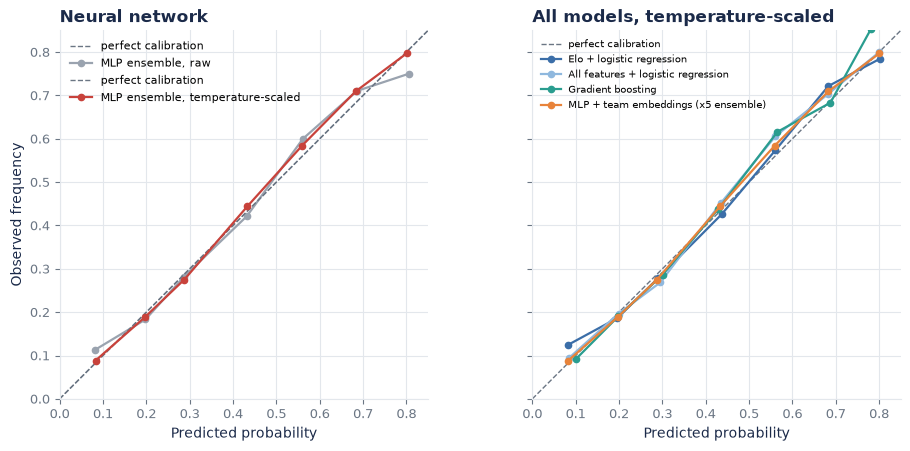

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
mlp_name = ens.name
P.reliability_plot(te.y, {"Raw": ens.predict_proba(te)}, ax=axes[0])
axes[0].lines[-1].set_color(P.COLORS["grey"])
axes[0].lines[-1].set_label("MLP ensemble, raw")
P.reliability_plot(te.y, {"Calibrated": cal[mlp_name].predict_proba(te)}, ax=axes[0])
axes[0].lines[-1].set_color(P.COLORS["red"])
axes[0].lines[-1].set_label("MLP ensemble, temperature-scaled")
axes[0].set_title("Neural network")
axes[0].legend(loc="upper left", fontsize=8)
P.reliability_plot(te.y, {k: m.predict_proba(te) for k, m in cal.items()}, ax=axes[1])
axes[1].set_title("All models, temperature-scaled")
axes[1].legend(loc="upper left", fontsize=7)
axes[1].set_ylabel("")
fig.tight_layout()
P.save(fig, "calibration")
plt.show()

In [10]:
raw_t, cal_t = cal_tab.xs("raw", level=1), cal_tab.xs("calibrated", level=1)
d_ll = raw_t.log_loss - cal_t.log_loss  # positive = scaling helped
n_ece_worse = int((cal_t.ece > raw_t.ece).sum())
display(
    Markdown(
        f"Temperature scaling changes test log-loss by {(-d_ll).min():+.4f} … {(-d_ll).max():+.4f} and worsens ECE for {n_ece_worse} of {len(raw_t)} models. "
        f"**It is not a reliable win here**: the fitted temperatures are close to 1 (the models were already roughly calibrated), only 494 validation matches fit them, "
        f"and test reliability curves from 753 matches are wide. It helps the Elo logistic regression most (it is the most over-confident, T = {temps.iloc[0]:.2f}). "
        f"We keep scaling as a cheap guard before the probabilities enter the simulation, but we do not claim it improves the network."
    )
)

Temperature scaling changes test log-loss by -0.0048 … +0.0007 and worsens ECE for 3 of 4 models. **It is not a reliable win here**: the fitted temperatures are close to 1 (the models were already roughly calibrated), only 494 validation matches fit them, and test reliability curves from 753 matches are wide. It helps the Elo logistic regression most (it is the most over-confident, T = 1.16). We keep scaling as a cheap guard before the probabilities enter the simulation, but we do not claim it improves the network.

## The fair head-to-head on the test seasons

All models calibrated on validation, scored once on the 753 test matches. Intervals are 95% bootstrap intervals over matches; the paired column is the bootstrap difference in log-loss **versus Elo + logistic regression** (negative = better than that baseline; an interval that includes 0 means "not distinguishable").

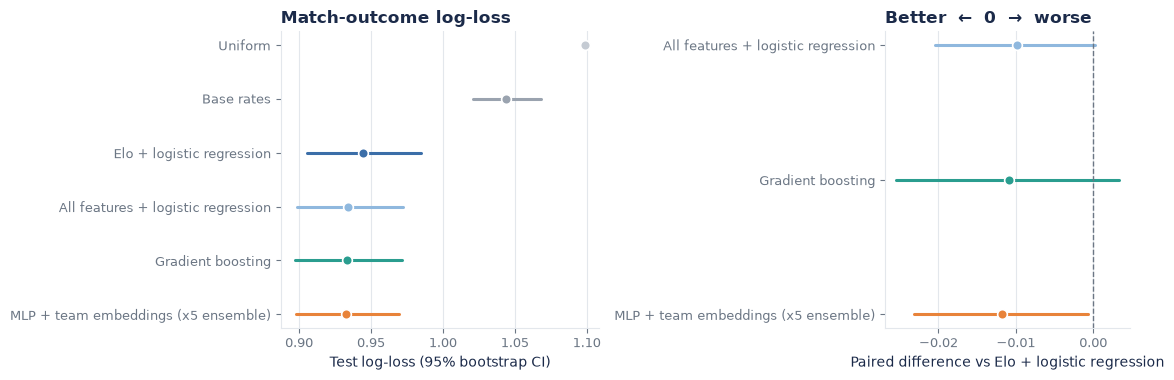

,log_loss,ll_lo,ll_hi,brier,rps,accuracy,ece,d_vs_elo,d_lo,d_hi
Uniform,1.0986,1.0986,1.0986,0.6667,0.2470,0.4887,0.0000,0.1545,0.1138,0.1934
Base rates,1.0439,1.0209,1.0683,0.6288,0.2374,0.4887,0.0066,0.0998,0.0655,0.1332
Elo + logistic regression,0.9441,0.9052,0.9848,0.5543,0.2006,0.5684,0.0330,0.0000,0.0000,0.0000
All features + logistic regression,0.9343,0.8989,0.9721,0.5494,0.1977,0.5764,0.0290,-0.0098,-0.0205,0.0002
Gradient boosting,0.9332,0.8973,0.9716,0.5481,0.1979,0.5870,0.0178,-0.0109,-0.0255,0.0033
MLP + team embeddings (x5 ensemble),0.9323,0.8981,0.9692,0.5487,0.1980,0.5710,0.0263,-0.0118,-0.0232,-0.0006


In [11]:
final = {"Uniform": baselines["Uniform"], "Base rates": baselines["Base rates"], **cal}
ref = final["Elo + logistic regression"].predict_proba(te)
rows = {}
for k, m in final.items():
    p = m.predict_proba(te)
    ll = per_match_log_loss(te.y, p)
    lo, hi = bootstrap_ci(ll)
    pb = (
        paired_bootstrap(te.y, p, ref, per_match_log_loss)
        if k != "Elo + logistic regression"
        else dict(diff=0.0, lo=0.0, hi=0.0, p_a_better=np.nan)
    )
    sc = score_all(te.y, p)
    rows[k] = {
        "log_loss": sc["log_loss"],
        "ll_lo": lo,
        "ll_hi": hi,
        "brier": sc["brier"],
        "rps": sc["rps"],
        "accuracy": sc["accuracy"],
        "ece": sc["ece"],
        "d_vs_elo": pb["diff"],
        "d_lo": pb["lo"],
        "d_hi": pb["hi"],
    }
head = pd.DataFrame(rows).T
X.save_json({k: {kk: float(vv) for kk, vv in v.items()} for k, v in rows.items()}, "test_metrics.json")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1]))
P.forest_plot(head, "log_loss", "ll_lo", "ll_hi", ax=axes[0])
axes[0].set_xlabel("Test log-loss (95% bootstrap CI)")
axes[0].set_title("Match-outcome log-loss")
sub = head.drop(["Uniform", "Base rates", "Elo + logistic regression"])
P.forest_plot(sub, "d_vs_elo", "d_lo", "d_hi", ax=axes[1], ref=0.0)
axes[1].set_xlabel("Paired difference vs Elo + logistic regression")
axes[1].set_title("Better  ←  0  →  worse")
fig.tight_layout()
P.save(fig, "model_comparison")
plt.show()
head[["log_loss", "ll_lo", "ll_hi", "brier", "rps", "accuracy", "ece", "d_vs_elo", "d_lo", "d_hi"]].round(4)

In [12]:
mlp = head.loc[ens.name]
p_mlp = final[ens.name].predict_proba(te)
vs = {
    k: paired_bootstrap(te.y, p_mlp, final[k].predict_proba(te), per_match_log_loss)
    for k in ["Elo + logistic regression", "All features + logistic regression", "Gradient boosting"]
}
vs_tab = (
    pd.DataFrame(vs)
    .T[["diff", "lo", "hi", "p_a_better"]]
    .rename(columns={"diff": "MLP minus model", "lo": "ci_lo", "hi": "ci_hi", "p_a_better": "P(MLP better)"})
)
vs_tab.round(4)

,MLP minus model,ci_lo,ci_hi,P(MLP better)
Elo + logistic regression,-0.0118,-0.0232,-0.0006,0.9805
All features + logistic regression,-0.0020,-0.0070,0.0029,0.7800
Gradient boosting,-0.0009,-0.0112,0.0098,0.5550


In [13]:
e, lr, g = vs["Elo + logistic regression"], vs["All features + logistic regression"], vs["Gradient boosting"]
display(
    Markdown(
        f"**Verdict (test seasons 2021/22-2025/26, 753 matches).**\n\n"
        f"* The calibrated 5-seed network reaches **{mlp.log_loss:.4f}** log-loss versus **{head.loc['Elo + logistic regression', 'log_loss']:.4f}** for Elo + logistic regression: "
        f"paired difference **{e['diff']:+.4f}** (95% CI {e['lo']:+.4f} … {e['hi']:+.4f}) — "
        f"{'a small improvement whose interval just excludes zero' if e['hi'] < 0 else 'not distinguishable from zero'}.\n"
        f"* Against the equally-informed baselines it does **not** win: vs all-features logistic regression {lr['diff']:+.4f} ({lr['lo']:+.4f} … {lr['hi']:+.4f}), "
        f"vs gradient boosting {g['diff']:+.4f} ({g['lo']:+.4f} … {g['hi']:+.4f}). Both intervals comfortably include zero, and the differences are of the same size as the seed-to-seed std ({seed_tab.test_log_loss.std():.4f}).\n"
        f"* The ablation says where the small gain over Elo-only comes from: the **engineered form features**, not the learned embeddings. "
        f"So the honest summary is: *the neural network ties a tuned linear model and gradient boosting on the same features; it is not better.* "
        f"RPS and Brier agree."
    )
)

**Verdict (test seasons 2021/22-2025/26, 753 matches).**

* The calibrated 5-seed network reaches **0.9323** log-loss versus **0.9441** for Elo + logistic regression: paired difference **-0.0118** (95% CI -0.0232 … -0.0006) — a small improvement whose interval just excludes zero.
* Against the equally-informed baselines it does **not** win: vs all-features logistic regression -0.0020 (-0.0070 … +0.0029), vs gradient boosting -0.0009 (-0.0112 … +0.0098). Both intervals comfortably include zero, and the differences are of the same size as the seed-to-seed std (0.0027).
* The ablation says where the small gain over Elo-only comes from: the **engineered form features**, not the learned embeddings. So the honest summary is: *the neural network ties a tuned linear model and gradient boosting on the same features; it is not better.* RPS and Brier agree.

**Why a tie is the expected outcome (and not a bug).** Three structural reasons: (1) *little data* — roughly 4,000 matches, of which 2,900 train, with 180 clubs and ~12 matches per club-season, so per-club embeddings are estimated from a few dozen observations; (2) *low signal-to-noise* — even a well-calibrated football model assigns near-uniform probabilities most of the time; (3) the *Elo rating already encodes club strength* in a single well-regularised number, leaving the embeddings only residual variation. The network is a perfectly good model here — it is just not a *better* one than a tuned linear model or boosted trees. A larger richer data source (domestic leagues, player-level data, betting odds) is where deep models start to pay off; see the limitations in notebook 04 and the model card.

## Saving the model

The artifact bundles the 5 networks, the fitted temperature, and a snapshot of the rating state after the last match in the data, so `ucl-predict` uses exactly the code path of training.

In [14]:
import shutil

if (MODELS_DIR / "ucl_mlp").exists():
    shutil.rmtree(MODELS_DIR / "ucl_mlp")
art = save_artifact(
    members,
    cal[ens.name].temperature,
    ds.state,
    MODELS_DIR / "ucl_mlp",
    extra={
        "as_of": str(ds.matches.date.max().date()),
        "elo_params": ds.elo_params.__dict__,
        "config": best_cfg.to_json(),
        "seeds": SEEDS,
        "test_log_loss": float(mlp.log_loss),
        "trained_on": "seasons 1992/93-2016/17 (early stopping on 2017/18-2020/21)",
    },
)
size_kb = sum(p.stat().st_size for p in art.rglob("*") if p.is_file()) / 1024
X.record_runtime("03_deep_model", time.perf_counter() - T0)
display(
    Markdown(
        f'Saved `{art.relative_to(art.parents[1])}` ({size_kb:.0f} KB). Try: `ucl-predict "Real Madrid" "Manchester City" --stage knockout`.'
    )
)

Saved `models/ucl_mlp` (477 KB). Try: `ucl-predict "Real Madrid" "Manchester City" --stage knockout`.